# EC442 Macroeconomics for MRes students

LSE, Autumn 2026 · Instructor: Matthias Doepke · Class notebook by Enrico D. Turri (e.turri@lse.ac.uk)

# Problem Set 4, Questions 1–2

**This notebook:**
- **Question 1:** a growth model with physical and human capital, where human capital is accumulated under decreasing returns
- **Question 2:** a version of the Lucas (1988) model, where human capital is accumulated under constant returns

## Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

# some useful plot defaults
plt.rcParams.update({'font.size': 12, 'lines.linewidth': 2, 'figure.figsize': (7, 3.5),
                     'axes.spines.top': False, 'axes.spines.right': False})

# Question 1

## The problem

The planner chooses next period's physical and human capital, $k'$ and $h'$. Producing $h'$ takes $h_2=(h'/B)^{1/\gamma}$ units of human capital, and the rest, $h_1=h-h_2$, is used to produce output:

$$
v(k,h)=\max_{k',h'}\Big\{\log\Big((1-\delta)k+Ak^\alpha\big(h-(h'/B)^{1/\gamma}\big)^{1-\alpha}-k'\Big)+\beta\, v(k',h')\Big\} \tag{1}
$$

with $k'\geq0$ and $0\le(h'/B)^{1/\gamma}\le h$.

- Parameters: $\beta=0.6$, $\alpha=0.3$, $\delta=0.6$, $\gamma=0.6$, $A=1$, $B=2$ (a model period is a decade)
- State space: $[0.4\bar k,1.5\bar k]\times[0.4\bar h,1.5\bar h]$, where $\bar k$ and $\bar h$ are the steady-state values

In [2]:
params = dict(beta=0.6, alpha=0.3, delta=0.6, gamma=0.6, A=1.0, B=2.0)

## Q1.2 The steady state

From the first-order conditions (see the solutions):

$$
r=\frac{1}{\beta}-1+\delta,\qquad h_2=(\beta\gamma B)^{\frac{1}{1-\gamma}},\qquad h=Bh_2^\gamma,\qquad h_1=h-h_2,\qquad \frac{k}{h_1}=\left(\frac{r}{\alpha A}\right)^{\frac{1}{\alpha-1}} \tag{2}
$$

In [3]:
def steady_state(params):
    beta, alpha, delta, gamma, A, B = (params[x] for x in ['beta', 'alpha', 'delta', 'gamma', 'A', 'B'])
    r = 1/beta - 1 + delta
    h2 = (beta*gamma*B)**(1/(1 - gamma))
    h = B*h2**gamma
    h1 = h - h2
    k = h1*(r/(alpha*A))**(1/(alpha - 1))
    return k, h, h1, h2

k_ss, h_ss, h1_ss, h2_ss = steady_state(params)
print(f'k = {k_ss:.4f}   h = {h_ss:.4f}   h1 = {h1_ss:.4f}   h2 = {h2_ss:.4f}')

k = 0.0999   h = 1.2219   h1 = 0.7820   h2 = 0.4399


- Physical capital is small relative to human capital: with $\alpha=0.3$, labour is the main input
- About a third of human capital, $h_2/h=\beta\gamma=0.36$, is used to produce next period's human capital

## Q1.5 Value function iteration on a two-dimensional grid

Same algorithm as in Problem Set 2, but now the state has two dimensions:
1. **Grids:** 100 points for $k$ and 100 for $h$, so $100\times100=10{,}000$ states, and $(k',h')$ are chosen on the same grids
2. **Period utility:** for every state $(k,h)$ and every choice $(k',h')$, compute $\log(c)$, with $-\infty$ where consumption would be negative
3. **Iterate** on $v_{n+1}=Tv_n$ from $v_0=0$ until $\|v_{n+1}-v_n\|_\infty<10^{-5}$

Trick to speed up things: compute the utility array once for all possible combinations over the grid

In [4]:
def make_grids(grid_points, k_ss, h_ss):
    k = np.linspace(0.4*k_ss, 1.5*k_ss, grid_points)
    h = np.linspace(0.4*h_ss, 1.5*h_ss, grid_points)
    return k, h

def utility_array(k, h, params):
    # U[i, j, i', j'] = log(c) at state (k_i, h_j) with choice (k_i', h_j')
    alpha, delta, gamma, A, B = (params[x] for x in ['alpha', 'delta', 'gamma', 'A', 'B'])
    h1 = h[:, None] - (h[None, :]/B)**(1/gamma)                                 # h1 for each (h, h')
    y = A*k[:, None, None]**alpha*np.maximum(h1, 0)[None, :, :]**(1 - alpha)    # output for each (k, h, h')
    c = (1 - delta)*k[:, None, None, None] + y[:, :, None, :] - k[None, None, :, None]
    feasible = (c > 0) & (h1 >= 0)[None, :, None, :]
    return np.where(feasible, np.log(np.maximum(c, 1e-300)), -np.inf)

def vfi(U, params, tol, max_iter):
    nk, nh = U.shape[0], U.shape[1]
    v = np.zeros((nk, nh))
    for n in range(max_iter):
        values = (U + params['beta']*v[None, None, :, :]).reshape(nk, nh, nk*nh)
        Tv, g = values.max(axis=2), values.argmax(axis=2)       # g: flat index of the optimal (k', h')
        dist = np.max(np.abs(Tv - v))
        v = Tv
        if dist < tol:
            return v, g // nh, g % nh, n + 1                     # value, indices of k' and h'
    print(f'Warning: no convergence after {max_iter} iterations')
    return v, g // nh, g % nh, max_iter

In [5]:
tol = 1e-5                     # convergence criterion
max_iter = 1_000               # safeguard: stop here if not converged

start = time.time()
k, h = make_grids(100, k_ss, h_ss)
U = utility_array(k, h, params)
v, gk, gh, iterations = vfi(U, params, tol, max_iter)
print(f'VFI converged: {iterations} iterations in {time.time() - start:.0f} seconds')

VFI converged: 25 iterations in 24 seconds


Much faster than standard VFI!

**Sanity check:** the steady state on the grid is the grid point that the policy maps closest to itself. It should be close to (2)

In [6]:
kp, hp = k[gk], h[gh]                                       # policy functions k'(k, h) and h'(k, h)
i, j = np.unravel_index(np.argmin((kp - k[:, None])**2 + (hp - h[None, :])**2), kp.shape)
print(f'grid: k = {k[i]:.4f}, h = {h[j]:.4f}     analytical (2): k = {k_ss:.4f}, h = {h_ss:.4f}')

grid: k = 0.0999, h = 1.2219     analytical (2): k = 0.0999, h = 1.2219


### Value and policy functions

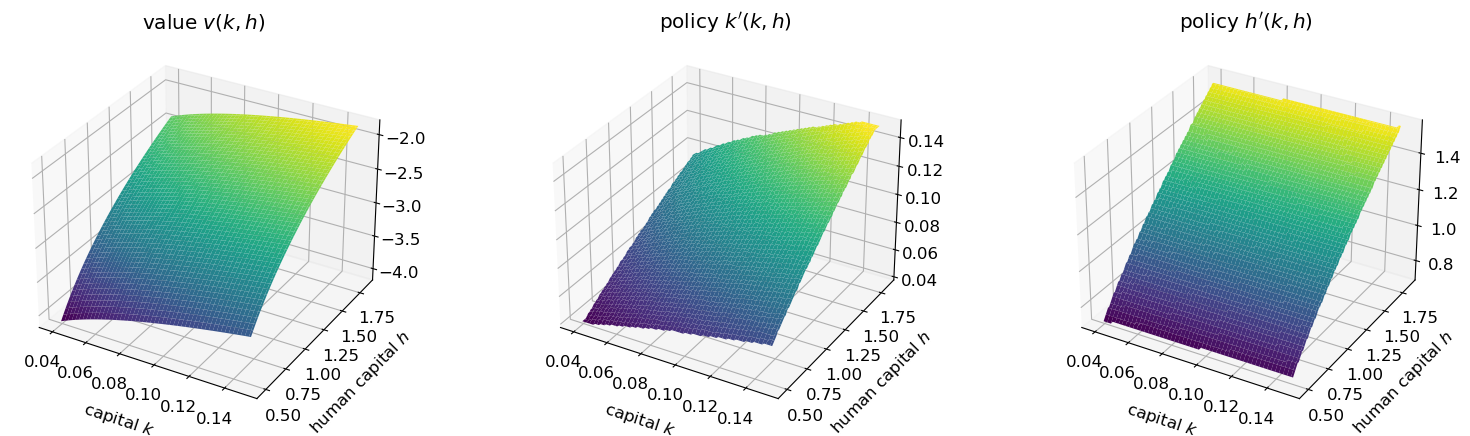

In [7]:
K, H = np.meshgrid(k, h, indexing='ij')
fig = plt.figure(figsize=(16, 4.5))
for pos, (Z, label) in enumerate([(v, 'value $v(k,h)$'), (kp, "policy $k'(k,h)$"), (hp, "policy $h'(k,h)$")]):
    ax = fig.add_subplot(1, 3, pos + 1, projection='3d')
    ax.plot_surface(K, H, Z, cmap='viridis', linewidth=0)
    ax.set_xlabel('capital $k$', labelpad=8); ax.set_ylabel('human capital $h$', labelpad=8)
    ax.set_title(label)
plt.tight_layout();

- The value function is increasing in both types of capital
- Tomorrow's physical capital $k'$ increases with both today's physical and human capital: at the steady state, its elasticity is about 0.4 with respect to $k$ and 0.6 with respect to $h$
- Tomorrow's human capital $h'$ depends on $h$, but hardly at all on $k$: on the whole grid, the planner uses about the same share of human capital to produce new human capital, between 0.35 and 0.39, close to its steady-state value $h_2/h=\beta\gamma=0.36$

### Time series from three initial conditions

Ten periods from (A) the steady state, (B) half the steady-state human capital, and (C) half the steady-state physical capital

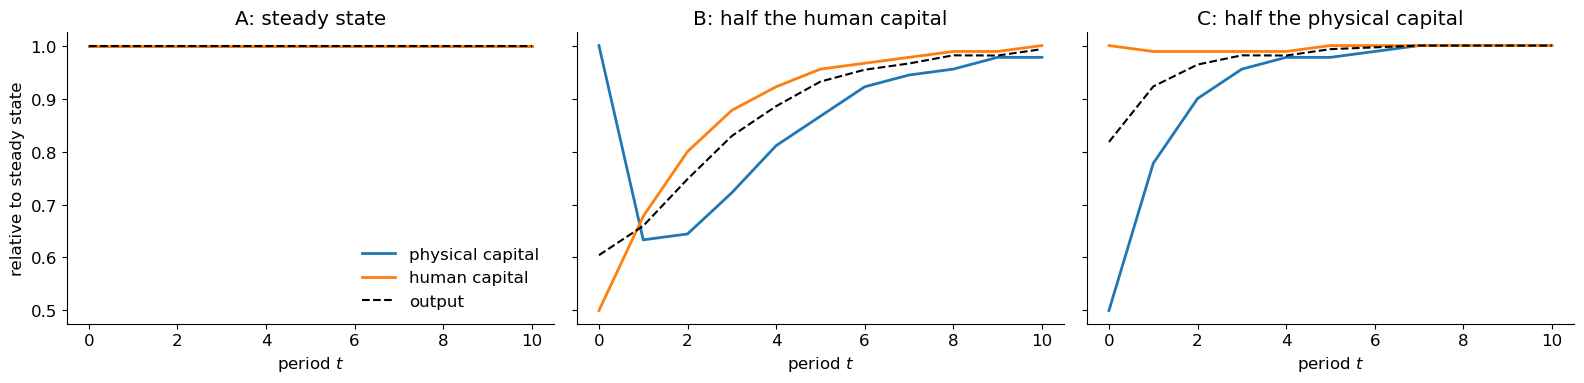

In [8]:
def simulate(k0, h0, k, h, gk, gh, params, T):
    alpha, gamma, A, B = (params[x] for x in ['alpha', 'gamma', 'A', 'B'])
    i, j = np.argmin(np.abs(k - k0)), np.argmin(np.abs(h - h0))
    path_k, path_h = [k[i]], [h[j]]
    for t in range(T + 1):                                   # one extra period to compute h1 at T
        i, j = gk[i, j], gh[i, j]
        path_k.append(k[i]); path_h.append(h[j])
    path_k, path_h = np.array(path_k), np.array(path_h)
    h1 = path_h[:-1] - (path_h[1:]/B)**(1/gamma)
    y = A*path_k[:-1]**alpha*h1**(1 - alpha)
    c = (1 - params['delta'])*path_k[:-1] + y - path_k[1:]     # consumption = output minus investment
    return path_k[:T + 1], path_h[:T + 1], y[:T + 1], c[:T + 1]

T = 10
y_ss = params['A']*k_ss**params['alpha']*h1_ss**(1 - params['alpha'])
c_ss = y_ss - params['delta']*k_ss
economies = {'A: steady state': (k_ss, h_ss), 'B: half the human capital': (k_ss, h_ss/2),
             'C: half the physical capital': (k_ss/2, h_ss)}

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for axi, (name, (k0, h0)) in zip(ax, economies.items()):
    pk, ph, py, pc = simulate(k0, h0, k, h, gk, gh, params, T)
    axi.plot(range(T + 1), pk/k_ss, label='physical capital')
    axi.plot(range(T + 1), ph/h_ss, label='human capital')
    axi.plot(range(T + 1), py/y_ss, 'k--', linewidth=1.5, label='output')
    axi.set_title(name); axi.set_xlabel('period $t$')
ax[0].set_ylabel('relative to steady state'); ax[0].legend(frameon=False, loc='lower right')
plt.tight_layout();

**Why are shortfalls of physical and human capital so different?**
- **Physical capital recovers fast** (Economy C): capital is produced one-for-one from output, and with $\delta=0.6$ most of it is replaced every period anyway, so 90% of the steady-state level is back after two periods. Human capital is barely affected
- **Human capital recovers slowly** (Economy B): it can only be produced with human capital under decreasing returns, and every unit used to produce it is taken away from final good production, where production is highly elastic to it. So the shortfall closes only gradually
- **A shortfall of human capital also lowers physical capital:** with less human capital, the marginal product of physical capital is lower, so the planner chooses a lower $k'$, until human capital has recovered

# Question 2: the Lucas (1988) model

## The problem

Human capital is now accumulated under constant returns, $h'=Bh_2$, so that $h_1=h-h'/B$:

$$
v(k,h)=\max_{k',h'}\Big\{\log\Big((1-\delta)k+Ak^\alpha\big(h-h'/B\big)^{1-\alpha}-k'\Big)+\beta\, v(k',h')\Big\} \tag{3}
$$

- Same parameters as in Question 1, but no $\gamma$
- There is no steady state: on the balanced growth path all quantities grow at the gross rate $g=\beta B$, and the ratio $h/k$ is constant (see the solutions):

$$
g=\beta B,\qquad \frac{\bar h}{\bar k}=\frac{1}{1-\beta}\left(\frac{B-1+\delta}{\alpha A}\right)^{\frac{1}{1-\alpha}} \tag{4}
$$

In [9]:
def bgp(params):
    beta, alpha, delta, A, B = (params[x] for x in ['beta', 'alpha', 'delta', 'A', 'B'])
    return beta*B, ((B - 1 + delta)/(alpha*A))**(1/(1 - alpha))/(1 - beta)

g, z_bgp = bgp(params)
print(f'growth factor g = {g:.2f} per decade,   h/k on the balanced growth path = {z_bgp:.2f}')

growth factor g = 1.20 per decade,   h/k on the balanced growth path = 27.32


## Q2.5 Using homogeneity: a one-dimensional problem

Q2.3 shows that $v(\lambda k,\lambda h)=\frac{1}{1-\beta}\log(\lambda)+v(k,h)$. With $\lambda=1/k$ and $z\equiv h/k$:

$$
v(k,h)=\frac{1}{1-\beta}\log(k)+\tilde v(z),\qquad \tilde v(z)\equiv v(1,z)
$$

So we only need $\tilde v$. Starting from $k=1$ and $h=z$, and writing $h'=z'k'$:

$$
\tilde v(z)=\max_{z'}\bigg\{\underbrace{\max_{k'}\Big[\log\big(1-\delta+A(z-z'k'/B)^{1-\alpha}-k'\big)+\frac{\beta}{1-\beta}\log(k')\Big]}_{u(z,z')}+\beta\,\tilde v(z')\bigg\} \tag{5}
$$

- **Grid:** 100 points for $z$ in $[0.4\bar h/\bar k,2\bar h/\bar k]$, and $z'$ chosen on the same grid
- The inner maximization over $k'$ does not depend on $\tilde v$, so we solve it **once**, for every pair $(z,z')$, by searching over a fine grid of $k'$ between $0$ and the largest feasible value, $\min\{Bz/z',\ 1-\delta+Az^{1-\alpha}\}$
- Then VFI on (5) is a one-dimensional problem, just like Problem Set 2

In [10]:
def inner_max(z, zp, params, search_points=2_000):
    # u(z, z') and the optimal k' (per unit of today's k), for arrays z and z'
    beta, alpha, delta, A, B = (params[x] for x in ['beta', 'alpha', 'delta', 'A', 'B'])
    z, zp = np.asarray(z, float)[:, None], np.asarray(zp, float)[None, :]
    k_max = np.minimum(B*z/zp, 1 - delta + A*z**(1 - alpha))             # largest feasible k'
    share = np.linspace(0, 1, search_points + 1)[1:-1]                      # k' = share * k_max, strictly inside
    kp = k_max[:, :, None]*share
    h1 = np.maximum(z[:, :, None] - zp[:, :, None]*kp/B, 0)
    c = 1 - delta + A*h1**(1 - alpha) - kp
    values = np.where(c > 0, np.log(np.maximum(c, 1e-300)) + beta/(1 - beta)*np.log(kp), -np.inf)
    return values.max(axis=2), k_max*share[values.argmax(axis=2)]

def vfi_ratio(z, u, params, tol, max_iter):
    v = np.zeros(len(z))
    for n in range(max_iter):
        values = u + params['beta']*v[None, :]
        Tv, g_z = values.max(axis=1), values.argmax(axis=1)
        dist = np.max(np.abs(Tv - v))
        v = Tv
        if dist < tol:
            return v, g_z, n + 1
    print(f'Warning: no convergence after {max_iter} iterations')
    return v, g_z, max_iter

start = time.time()
z = np.linspace(0.4*z_bgp, 2*z_bgp, 100)
u, kp_z = inner_max(z, z, params)
v_tilde, g_z, iterations = vfi_ratio(z, u, params, tol, max_iter)
growth = kp_z[np.arange(len(z)), g_z]                      # k'/k at each z
print(f'VFI converged: {iterations} iterations in {time.time() - start:.1f} seconds')

VFI converged: 24 iterations in 1.7 seconds


**Sanity checks against (4):** at the balanced-growth ratio, the policy should keep $z$ unchanged, and capital should grow by the factor $g=\beta B$

fixed point of the policy: z = 27.27   (analytical 27.32)
growth of capital there:   k'/k = 1.200   (analytical 1.200)


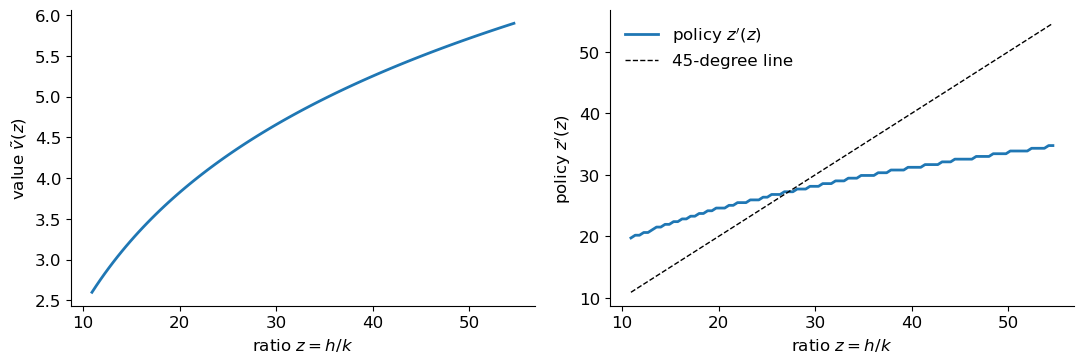

In [11]:
i = np.argmin(np.abs(z[g_z] - z))                          # grid point that the policy maps closest to itself
print(f'fixed point of the policy: z = {z[i]:.2f}   (analytical {z_bgp:.2f})')
print(f"growth of capital there:   k'/k = {growth[i]:.3f}   (analytical {g:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(z, v_tilde)
ax[0].set_xlabel('ratio $z=h/k$'); ax[0].set_ylabel(r'value $\tilde v(z)$')
ax[1].plot(z, z[g_z], label="policy $z'(z)$")
ax[1].plot(z, z, 'k--', linewidth=1, label='45-degree line')
ax[1].set_xlabel('ratio $z=h/k$'); ax[1].set_ylabel("policy $z'(z)$"); ax[1].legend(frameon=False)
plt.tight_layout();

- The policy for the ratio crosses the 45-degree line once, at $\bar h/\bar k$: from any ratio, the economy moves towards the balanced-growth ratio
- The policy is much flatter than the 45-degree line, so the ratio converges fast: from half the balanced-growth ratio, it reaches about 80% of it in one period, and from twice the ratio, about 130%

### Value and policy functions in $(k,h)$

The problem set asks for three-dimensional surfaces. Homogeneity gives them without further computation: $v(k,h)=\frac{1}{1-\beta}\log(k)+\tilde v(h/k)$, and the policies are homogeneous of degree one, $k'(k,h)=k\,\kappa(h/k)$ and $h'(k,h)=z'(h/k)\,k'(k,h)$, where $\kappa(z)$ is the optimal $k'$ per unit of $k$. We plot them for $k\in[1,2]$, and values of $h$ for which $h/k$ stays on the grid, interpolating between grid points

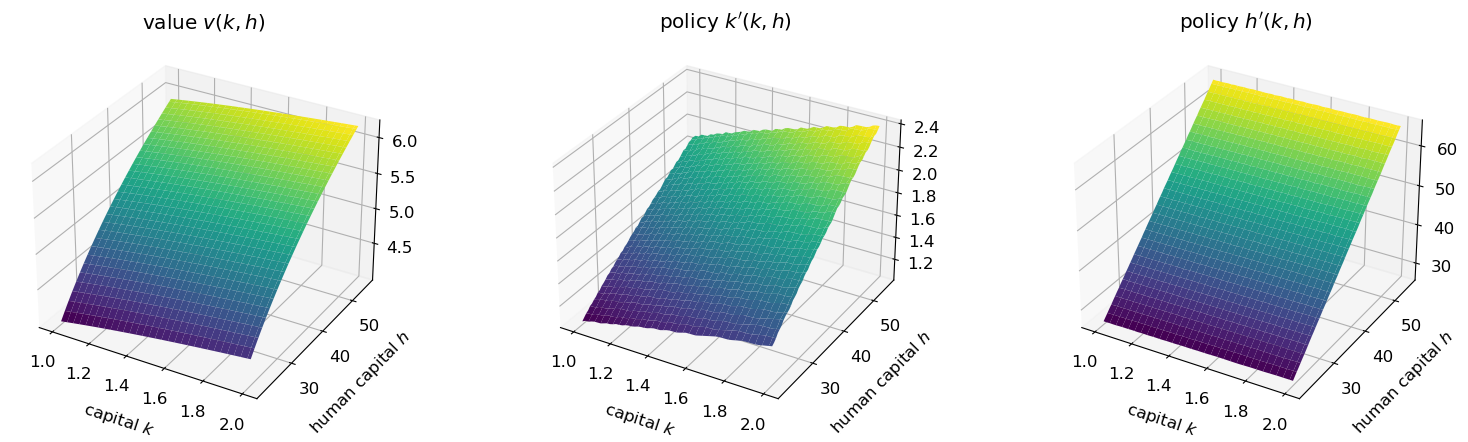

In [12]:
k_plot = np.linspace(1, 2, 60)
h_plot = np.linspace(0.4*z_bgp*2, 2*z_bgp*1, 60)           # so that h/k stays in [0.4, 2] times h/k on the BGP
K, H = np.meshgrid(k_plot, h_plot, indexing='ij')
Zr = H/K
V = np.log(K)/(1 - params['beta']) + np.interp(Zr, z, v_tilde)
KP = K*np.interp(Zr, z, growth)
HP = np.interp(Zr, z, z[g_z])*KP

fig = plt.figure(figsize=(16, 4.5))
for pos, (Zs, label) in enumerate([(V, 'value $v(k,h)$'), (KP, "policy $k'(k,h)$"), (HP, "policy $h'(k,h)$")]):
    ax = fig.add_subplot(1, 3, pos + 1, projection='3d')
    ax.plot_surface(K, H, Zs, cmap='viridis', linewidth=0)
    ax.set_xlabel('capital $k$', labelpad=8); ax.set_ylabel('human capital $h$', labelpad=8)
    ax.set_title(label)
plt.tight_layout();

### Time series from three initial conditions

Same three economies as in Question 1, now in logs, so that balanced growth shows up as straight lines: (A) on the balanced growth path, $k_0=1$ and $h_0=\bar h/\bar k$, (B) half as much human capital, and (C) half as much physical capital

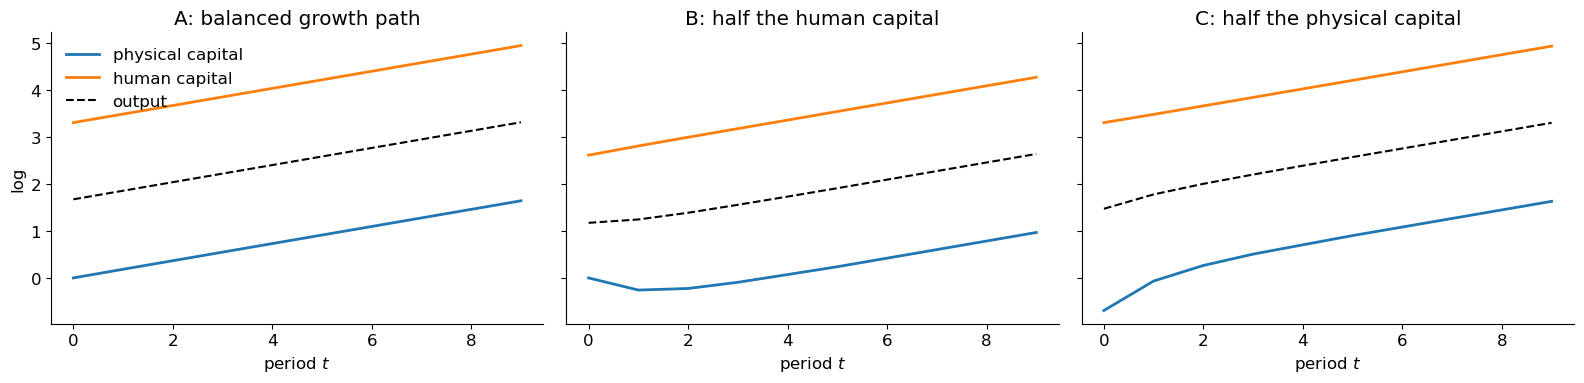

In [13]:
def simulate_lucas(k0, h0, z, v_tilde, params, T):
    alpha, A, B = params['alpha'], params['A'], params['B']
    path_k, path_h, path_y = [k0], [h0], []
    for t in range(T):
        u_t, kp_t = inner_max([path_h[-1]/path_k[-1]], z, params)
        j = np.argmax(u_t[0] + params['beta']*v_tilde)       # optimal z'
        k_next = path_k[-1]*kp_t[0, j]                        # k' = k * (k' per unit of k)
        h_next = z[j]*k_next
        path_y.append(A*path_k[-1]**alpha*(path_h[-1] - h_next/B)**(1 - alpha))
        path_k.append(k_next); path_h.append(h_next)
    return np.array(path_k[:T]), np.array(path_h[:T]), np.array(path_y)

T = 10
economies = {'A: balanced growth path': (1.0, z_bgp), 'B: half the human capital': (1.0, z_bgp/2),
             'C: half the physical capital': (0.5, z_bgp)}
paths = {name: simulate_lucas(k0, h0, z, v_tilde, params, T) for name, (k0, h0) in economies.items()}

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for axi, (name, (pk, ph, py)) in zip(ax, paths.items()):
    axi.plot(range(T), np.log(pk), label='physical capital')
    axi.plot(range(T), np.log(ph), label='human capital')
    axi.plot(range(T), np.log(py), 'k--', linewidth=1.5, label='output')
    axi.set_title(name); axi.set_xlabel('period $t$')
ax[0].set_ylabel('log'); ax[0].legend(frameon=False, loc='upper left')
plt.tight_layout();

**Do the economies catch up?** Compare the levels with Economy A at the end of the simulation

In [14]:
pk_A, ph_A, py_A = paths['A: balanced growth path']
for name in list(paths)[1:]:
    pk, ph, py = paths[name]
    print(f'{name}:  log gap in k {np.log(pk[-1]/pk_A[-1]):+.3f},  in h {np.log(ph[-1]/ph_A[-1]):+.3f},  '
          f'in y {np.log(py[-1]/py_A[-1]):+.3f}')

B: half the human capital:  log gap in k -0.675,  in h -0.675,  in y -0.675
C: half the physical capital:  log gap in k -0.012,  in h -0.012,  in y -0.012


- After a few periods, all three economies grow at the same rate $g=\beta B$, but **none of them catches up**: initial shortfalls have permanent effects on the levels
- **Economy B** ends up about half as rich as Economy A, forever
- **Economy C** also ends up below Economy A, but only slightly, by about 1%, because physical capital is a small part of total capital: $\bar h/\bar k\approx27$
- This is the key difference from Question 1. There, human capital is accumulated under decreasing returns, so there is a steady state and every economy converges back to it. Here, with constant returns, there is no force pulling the levels back: growth is endogenous, and history matters

# Takeaways

- **VFI works in two dimensions**, but if you can, exploit homogeneity to reduce dimensionality
- **Trick to speed things up:** inner maximizations can be solved once, before iterating
- **Physical and human capital are not alike:** physical capital is quickly rebuilt, while human capital is slow to accumulate; the key difference here is that physical capital is produced from both physical and human capital, human capital only from itself
- **Decreasing versus constant returns:** with decreasing returns in human capital the economy converges back to its steady state; with constant returns, growth is endogenous and changes in initial conditions have permanent level effects

**References**

Lucas, R. E., Jr. (1988): "On the Mechanics of Economic Development," *Journal of Monetary Economics*, 22(1), 3–42.

Uzawa, H. (1965): "Optimum Technical Change in an Aggregative Model of Economic Growth," *International Economic Review*, 6(1), 18–31.

**Running this notebook**

Times are for a MacBook Air (Apple M2, 8 GB of RAM), where the whole notebook takes about 15 seconds. The notebook needs about 2.5 GB of free memory